# FashionMNIST EDM diffusion experiment

This notebook is organized as imports, data/noise setup, model, training, and evaluation.

In [ ]:
import matplotlib.pyplot as plt
from scipy.linalg import sqrtm
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.amp import GradScaler, autocast
from torchvision.models import inception_v3
from tqdm import tqdm
from collections import namedtuple
from typing import Optional, Tuple
from torch.utils.data import default_collate, DataLoader, Dataset, random_split
from torchvision.datasets import CelebA, FashionMNIST
import torchvision.transforms as T
from pathlib import Path

# Keep experiments reproducible
seed = 42
torch.manual_seed(seed)
np.random.seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)


In [ ]:
DataInfo = namedtuple('DataInfo', 'image_channels image_size num_classes sigma_data')
DataLoaders = namedtuple('DataLoaders', 'train valid')


def load_dataset_and_make_dataloaders(
        dataset_name: str,
        root_dir: str,
        batch_size: int,
        num_workers: int = 0,
        pin_memory: bool = False
    ) -> Tuple[DataLoaders, DataInfo]:

    train_dataset, valid_dataset, data_info = load_dataset(dataset_name, root_dir)
    dl = make_dataloaders(train_dataset, valid_dataset, data_info.num_classes, batch_size, num_workers, pin_memory)
    return dl, data_info


def load_dataset(dataset_name='FashionMNIST', root_dir='data') -> Tuple[Dataset, Dataset, DataInfo]:

    match dataset_name:

        case 'FashionMNIST':
            t = T.Compose([T.ToTensor(), T.Pad(2), T.Normalize(mean=(0.5,), std=(0.5,))])
            train_dataset = FashionMNIST(root_dir, download=True, transform=t)
            train_dataset, valid_dataset = random_split(train_dataset, [50000, 10000], generator=torch.Generator().manual_seed(seed))
            #train_dataset, valid_dataset = random_split(train_dataset, [500, 59500])
            num_classes = 10

        case 'CelebA':
            t = T.Compose([T.ToTensor(), T.CenterCrop(178), T.Resize(128, antialias=True), T.Normalize(mean=(0.5,), std=(0.5,))])
            train_dataset = CelebA(root_dir, download=True, transform=t)
            train_dataset, valid_dataset = random_split(train_dataset, [150000, 12770], generator=torch.Generator().manual_seed(seed))
            num_classes = None

        case other:
            raise RuntimeError('Unknown dataset: ' + other)

    #x, _ = next(iter(DataLoader(train_dataset, batch_size=100, shuffle=True)))
    x, _ = next(iter(DataLoader(train_dataset, batch_size=10000, shuffle=True)))
    _, c, h, w = x.size()
    assert h == w
    sigma_data = x.std()

    return train_dataset, valid_dataset, DataInfo(c, h, num_classes, sigma_data)


def make_dataloaders(
        train_dataset: Dataset,
        valid_dataset: Dataset,
        num_classes: Optional[int],
        batch_size: int,
        num_workers: int = 0,
        pin_memory: bool = False
    ) -> DataLoaders:

    collate_fn = default_collate if num_classes is not None else lambda batch: (default_collate(batch)[0], None)
    kwargs = {'collate_fn': collate_fn, 'num_workers': num_workers, 'persistent_workers': (num_workers > 0), 'pin_memory': pin_memory}

    return DataLoaders(
        train=DataLoader(train_dataset, batch_size=batch_size, shuffle=True, **kwargs),
        valid=DataLoader(valid_dataset, batch_size=2 * batch_size, **kwargs)
    )


# Model architecture

The model is defined here before the dataset and training sections.

In [ ]:
class Model(nn.Module):
    def __init__(
        self,
        image_channels: int,
        nb_channels: int,
        num_blocks: int,
        cond_channels: int,
    ) -> None:
        super().__init__()
        self.noise_emb = NoiseEmbedding(cond_channels)  #Encodes a 1D noise scalar into a vector
        self.conv_in = nn.Conv2d(image_channels, nb_channels, kernel_size=3, padding=1) #Convolutional layer that takes the input image and applies a 3x3 kernel to it, with padding of 1 to maintain the spatial dimensions.
        self.blocks = nn.ModuleList([
            ResidualBlock(nb_channels, cond_channels) for _ in range(num_blocks)
        ])  #List of residual blocks. Each block consists of two convolutional layers with batch normalization and ReLU activation.
        self.conv_out = nn.Conv2d(nb_channels, image_channels, kernel_size=3, padding=1)    #Final convolutional layer that reduces the number of channels back to the original image channels.

        # Apply custom initialization
        self._initialize_weights()

    def forward(self, noisy_input: torch.Tensor, c_noise: torch.Tensor) -> torch.Tensor:
        # Generate noise embedding
        cond = self.noise_emb(c_noise)  # [batch_size, cond_channels]

        # Pass through input convolution
        x = self.conv_in(noisy_input)

        # Pass through residual blocks with noise conditioning
        for block in self.blocks:
            x = block(x, cond)

        # Output convolution to return the denoised image
        return self.conv_out(x)

    def _initialize_weights(self):
        """Custom weight initialization."""
        # Initialize conv_out weights to 0
        nn.init.constant_(self.conv_out.weight, 0)
        if self.conv_out.bias is not None:
            nn.init.constant_(self.conv_out.bias, 0)




class NoiseEmbedding(nn.Module):
    """
    This module converts a 1D input (e.g., a timestep or noise level) into a higher-dimensional vector using sinusoidal projections.
    The input is a 1D tensor of shape (batch_size,) and the output is a 2D tensor of shape (batch_size, cond_channels).
    It mimics Fourier feature encoding:
        Projects input to a higher dimension using random frequencies (self.weight).
        Applies sin and cos to get a periodic, non-linear representation of the input.
    This is useful for capturing patterns with different frequencies — often used in diffusion models or NeRFs.
    """
    def __init__(self, cond_channels: int) -> None:
        super().__init__()
        assert cond_channels % 2 == 0
        self.register_buffer('weight', torch.randn(1, cond_channels // 2))

    def forward(self, input: torch.Tensor) -> torch.Tensor:
        assert input.ndim == 1
        f = 2 * torch.pi * input.unsqueeze(1) @ self.weight
        return torch.cat([f.cos(), f.sin()], dim=-1)


class ResidualBlock(nn.Module):
    def __init__(self, nb_channels: int, cond_channels: int):
        super().__init__()
        self.norm1 = nn.BatchNorm2d(nb_channels, affine=False)
        self.conv1 = nn.Conv2d(nb_channels, nb_channels, kernel_size=3, stride=1, padding=1)
        self.norm2 = nn.BatchNorm2d(nb_channels, affine=False)
        self.conv2 = nn.Conv2d(nb_channels, nb_channels, kernel_size=3, stride=1, padding=1)

        # Predict affine parameters
        self.gamma1 = nn.Linear(cond_channels, nb_channels)
        self.beta1 = nn.Linear(cond_channels, nb_channels)
        self.gamma2 = nn.Linear(cond_channels, nb_channels)
        self.beta2 = nn.Linear(cond_channels, nb_channels)

        # Apply custom initialization
        self._initialize_weights()

    def forward(self, x, cond):
        gamma1 = self.gamma1(cond).unsqueeze(-1).unsqueeze(-1)
        beta1 = self.beta1(cond).unsqueeze(-1).unsqueeze(-1)
        y = self.norm1(x)
        y = gamma1 * y + beta1
        y = F.leaky_relu(self.conv1(y), negative_slope=0.2)

        gamma2 = self.gamma2(cond).unsqueeze(-1).unsqueeze(-1)
        beta2 = self.beta2(cond).unsqueeze(-1).unsqueeze(-1)
        y = self.norm2(y)
        y = gamma2 * y + beta2
        y = F.leaky_relu(self.conv2(y), negative_slope=0.2)

        return x + y

    def _initialize_weights(self):
        """Custom weight initialization."""
        # Initialize conv2 weights to 0
        nn.init.constant_(self.conv2.weight, 0)
        if self.conv2.bias is not None:
            nn.init.constant_(self.conv2.bias, 0)




In [ ]:
# Dataset, device, and diffusion preconditioning
gpu = torch.cuda.is_available()
device = torch.device('cuda:0' if gpu else 'cpu')

dl, info = load_dataset_and_make_dataloaders(
    dataset_name='FashionMNIST',
    root_dir='data',
    batch_size=256,
    num_workers=2 if gpu else 0,
    pin_memory=gpu,
)
sigma_data = info.sigma_data.to(device)
train_dl = dl.train
test_dl = dl.valid


def sample_sigma(n, loc=-1.2, scale=1.2, sigma_min=2e-3, sigma_max=80):
    """Sample EDM noise levels from a clipped log-normal distribution."""
    return (torch.randn(n, device=device) * scale + loc).exp().clamp(sigma_min, sigma_max)


def add_noise_to_image(image, sigma, p_noise_mean=0, p_noise_std=1):
    """Add Gaussian noise without clipping, as required by the EDM target."""
    epsilon = torch.randn_like(image) * p_noise_std + p_noise_mean
    return image + sigma.view(-1, 1, 1, 1) * epsilon


def c_in(sigma):
    return 1 / torch.sqrt(sigma_data**2 + sigma**2)


def c_out(sigma):
    return sigma * sigma_data / torch.sqrt(sigma_data**2 + sigma**2)


def c_skip(sigma):
    return sigma_data**2 / (sigma_data**2 + sigma**2)


def c_noise(sigma):
    return torch.log(sigma) / 4


# Sampling and evaluation

The cells below generate samples and calculate the current evaluation metrics.

In [ ]:
# Training configuration and utilities
scaler = GradScaler('cuda', enabled=gpu)

eta = 0.005
image_channels = 1
nb_channels = 128
num_blocks = 8
cond_channels = 64
nb_epochs = 50
checkpoint_path = Path('checkpoints/fashionmnist_edm_best.pt')

model = Model(image_channels, nb_channels, num_blocks, cond_channels).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=eta)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', patience=5, factor=0.5, min_lr=1e-6
)


def compute_denoising_batch(images):
    """Create an EDM-preconditioned input and target for one image batch."""
    batch_size = images.size(0)
    sigma = sample_sigma(batch_size)
    noised_images = add_noise_to_image(images, sigma)

    c_in_values = c_in(sigma).view(-1, 1, 1, 1)
    c_out_values = c_out(sigma).view(-1, 1, 1, 1)
    c_skip_values = c_skip(sigma).view(-1, 1, 1, 1)
    c_noise_values = c_noise(sigma)

    x_batch = noised_images * c_in_values
    t_batch = (images - c_skip_values * noised_images) / c_out_values
    return x_batch, c_noise_values, t_batch


def train_model(model, optimizer, scheduler, nb_epochs, checkpoint_path):
    """Train the model, retain the best validation checkpoint, and return history."""
    history = {'train_loss': [], 'valid_loss': [], 'learning_rate': []}
    best_val_loss = float('inf')
    checkpoint_path.parent.mkdir(parents=True, exist_ok=True)

    for epoch in tqdm(range(nb_epochs), desc='Training'):
        model.train()
        total_train_loss = 0.0

        for images, _ in train_dl:
            images = images.to(device, non_blocking=gpu)
            x_batch, c_noise_values, t_batch = compute_denoising_batch(images)
            optimizer.zero_grad(set_to_none=True)

            with autocast(device_type=device.type, enabled=gpu):
                output = model(x_batch, c_noise_values)
                loss = criterion(output, t_batch)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            total_train_loss += loss.item()

        avg_train_loss = total_train_loss / len(train_dl)

        model.eval()
        total_val_loss = 0.0
        with torch.no_grad():
            for images, _ in test_dl:
                images = images.to(device, non_blocking=gpu)
                x_batch, c_noise_values, t_batch = compute_denoising_batch(images)
                with autocast(device_type=device.type, enabled=gpu):
                    output = model(x_batch, c_noise_values)
                    loss = criterion(output, t_batch)
                total_val_loss += loss.item()

        avg_val_loss = total_val_loss / len(test_dl)
        scheduler.step(avg_val_loss)
        current_lr = optimizer.param_groups[0]['lr']

        history['train_loss'].append(avg_train_loss)
        history['valid_loss'].append(avg_val_loss)
        history['learning_rate'].append(current_lr)

        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            torch.save({
                'epoch': epoch + 1,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'scheduler_state_dict': scheduler.state_dict(),
                'validation_loss': best_val_loss,
                'seed': seed,
            }, checkpoint_path)

        print(
            f'Epoch [{epoch + 1}/{nb_epochs}], '
            f'Training Loss: {avg_train_loss:.4f}, '
            f'Validation Loss: {avg_val_loss:.4f}, '
            f'Learning Rate: {current_lr:.2e}'
        )

    return history


# Train once this cell is executed. Sampling/evaluation cells use the same model.
history = train_model(model, optimizer, scheduler, nb_epochs, checkpoint_path)

# Evaluate and sample from the best validation checkpoint.
if checkpoint_path.exists():
    best_checkpoint = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(best_checkpoint['model_state_dict'])
    print(f"Loaded best checkpoint from epoch {best_checkpoint['epoch']} (validation loss: {best_checkpoint['validation_loss']:.4f})")


Training:   2%|▏         | 1/50 [01:27<1:11:44, 87.84s/it]

Epoch [1/50], Training Loss: 2.9847, Validation Loss: 0.5209, Learning Rate: 5.00e-03


Training:   4%|▍         | 2/50 [02:56<1:10:48, 88.52s/it]

Epoch [2/50], Training Loss: 0.3914, Validation Loss: 0.3360, Learning Rate: 5.00e-03


Training:   6%|▌         | 3/50 [04:28<1:10:31, 90.03s/it]

...

Epoch [48/50], Training Loss: 0.1521, Validation Loss: 0.1552, Learning Rate: 1.25e-03


Training:  98%|█████████▊| 49/50 [1:18:39<01:38, 98.24s/it]

Epoch [49/50], Training Loss: 0.1519, Validation Loss: 0.1535, Learning Rate: 1.25e-03


Training: 100%|██████████| 50/50 [1:20:18<00:00, 96.36s/it]

Epoch [50/50], Training Loss: 0.1520, Validation Loss: 0.1524, Learning Rate: 1.25e-03
Loaded best checkpoint from epoch 46 (validation loss: 0.1506)


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=Inception_V3_Weights.IMAGENET1K_V1`. You can also use `weights=Inception_V3_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 112MB/s]
Generating Images: 100%|██████████| 20/20 [00:55<00:00,  2.75s/it]


FID score: 68.42425020655686


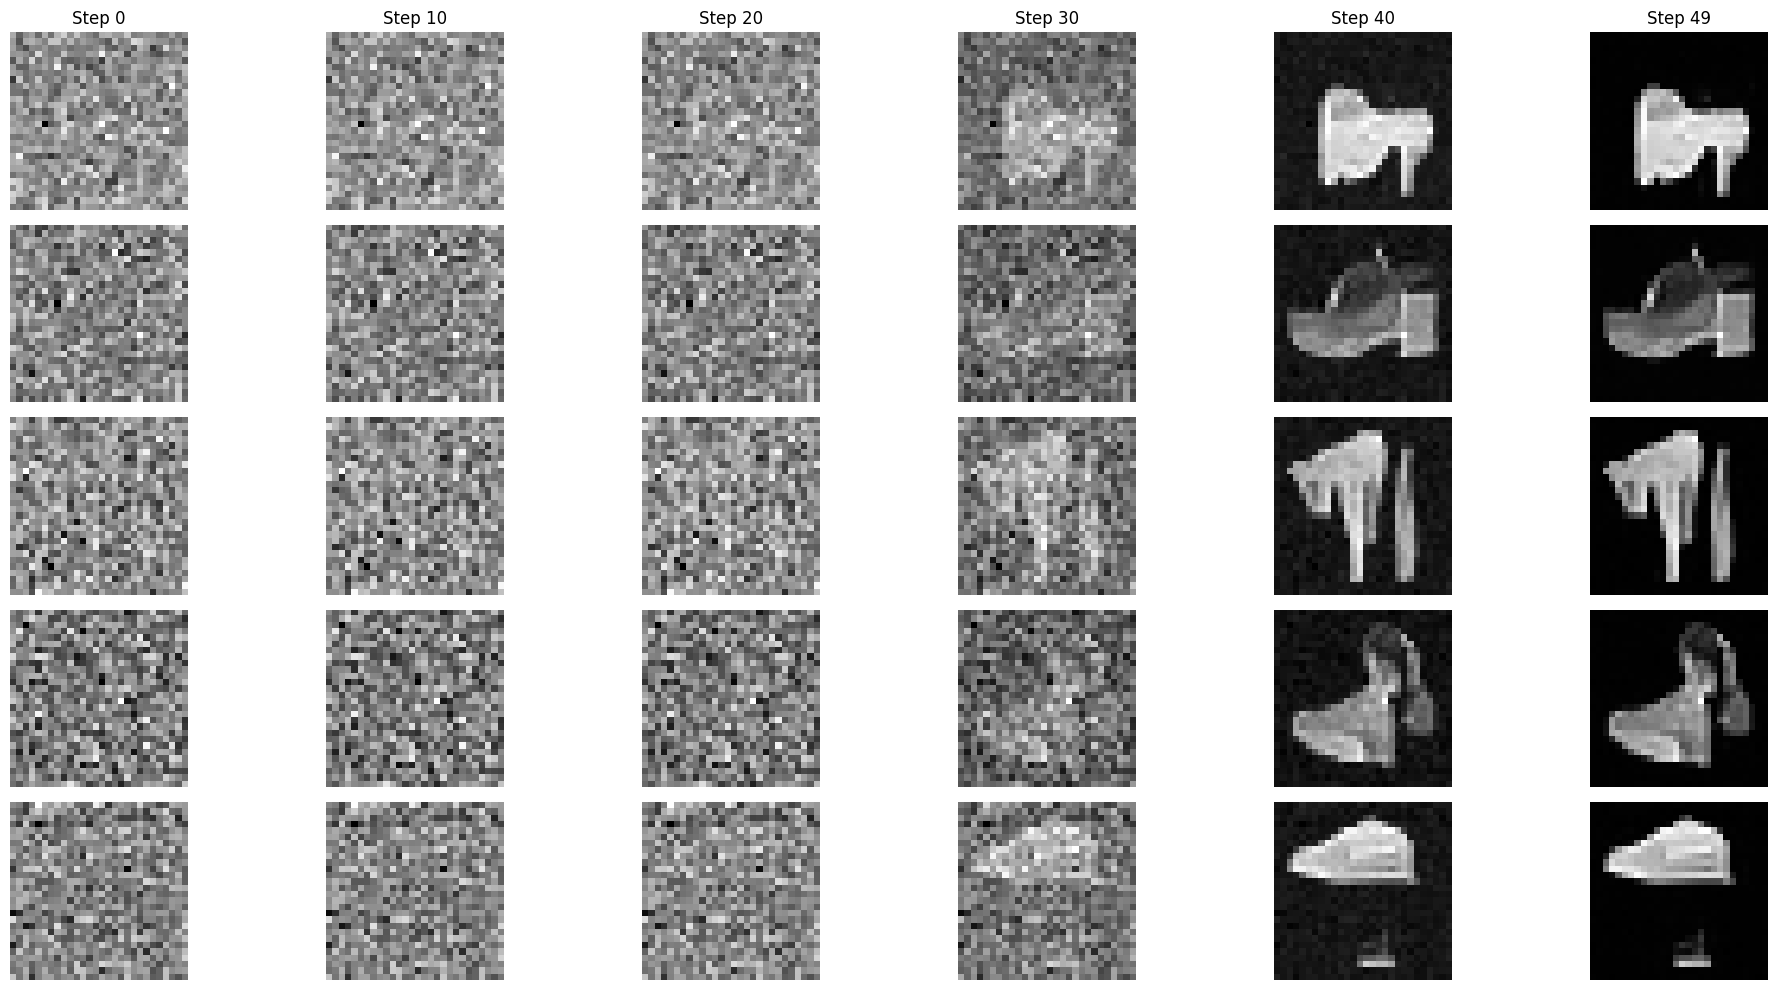

In [ ]:
# Load pre-trained InceptionV3 model (See appendix for details)
inception_model = inception_v3(pretrained=True, transform_input=False).to(device)
inception_model.fc = nn.Identity()  # Remove the final classification layer
inception_model.eval()  # Set the model to evaluation mode

# Define a transformation to convert 1-channel to 3-channel and resize to 299x299
preprocess = T.Compose([
    T.Resize((299, 299)),
    T.Lambda(lambda x: x.repeat(1, 3, 1, 1) if x.size(1) == 1 else x),  # Ensure 3 channels
    T.Normalize(mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]),
])

def get_inception_features(images, model, device, preprocess, batch_size=50):
    """
    Extract features from images using the InceptionV3 model.

    Args:
        images (torch.Tensor): Tensor of images with shape (N, C, H, W).
        model (nn.Module): Pretrained InceptionV3 model.
        device (torch.device): Computing device.
        preprocess (callable): Preprocessing function.
        batch_size (int): Batch size for processing images.

    Returns:
        np.ndarray: Extracted features of shape (N, feature_dim).
    """
    features = []
    with torch.no_grad():
        for i in range(0, len(images), batch_size):
            batch = images[i:i+batch_size].to(device)
            # Convert from [-1, 1] to [0, 1]
            batch = (batch + 1) / 2
            batch = preprocess(batch)
            outputs = model(batch)
            features.append(outputs.cpu().numpy())
    features = np.concatenate(features, axis=0)
    return features

def calculate_frechet_distance(mu1, sigma1, mu2, sigma2):
    """Calculate the Frechet Distance between two multivariate Gaussians."""
    diff = mu1 - mu2
    covmean = sqrtm(sigma1 @ sigma2)
    if np.iscomplexobj(covmean):
        covmean = covmean.real
    fid = np.sum(diff ** 2) + np.trace(sigma1 + sigma2 - 2 * covmean)
    return fid


# Testing loop
model.eval()

def sample_initial_noise(shape, sigma):
    return torch.randn(shape, device=sigma.device) * sigma

def build_sigma_schedule(steps, rho=7, sigma_min=2e-3, sigma_max=80):
    min_inv_rho = sigma_min ** (1 / rho)
    max_inv_rho = sigma_max ** (1 / rho)
    sigmas = (max_inv_rho + torch.linspace(0, 1, steps) * (min_inv_rho - max_inv_rho)) ** rho
    return sigmas

# Define the denoising function using Euler's method
def D(x, sigma):
    c_skip_sigma = c_skip(sigma).view(-1, 1, 1, 1)
    c_out_sigma = c_out(sigma).view(-1, 1, 1, 1)
    c_in_sigma = c_in(sigma).view(-1, 1, 1, 1)
    c_noise_sigma = c_noise(sigma)  # [batch_size]
    return c_skip_sigma * x + c_out_sigma * model(c_in_sigma * x, c_noise_sigma)

def euler_step(x, sigmas, save_steps=None):
    batch_size = x.size(0)
    intermediate_images = [[] for _ in range(batch_size)]  # List of lists to store intermediate images for each image
    for i, sigma in enumerate(sigmas):
        sigma = sigma.to(x.device)
        sigma = sigma.expand(batch_size)  # Shape: [batch_size]
        with torch.no_grad():
            x_denoised = D(x, sigma)

        if i < len(sigmas) - 1:
            sigma_next = sigmas[i + 1].to(x.device)
            sigma_next = sigma_next.expand(batch_size)
        else:
            sigma_next = torch.full((batch_size,), 2e-3, device=x.device)  # sigma_min

        d = (x - x_denoised) / (sigma.view(-1, 1, 1, 1))

        sigma_diff = (sigma_next - sigma).view(-1, 1, 1, 1)
        x = x + d * sigma_diff

        # Save intermediate images if specified
        if save_steps and i in save_steps:
            for j in range(batch_size):
                intermediate_images[j].append(x[j].clone().cpu())

    return x, intermediate_images

def generate_images(sigmas, num_images=1000, batch_size=50, save_steps=None):
    """
    Generate a specified number of images using the diffusion model.

    Args:
        sigmas (torch.Tensor): Schedule of sigma values.
        num_images (int): Total number of images to generate.
        batch_size (int): Number of images per batch.
        save_steps (list, optional): Steps at which to save intermediate images.

    Returns:
        torch.Tensor: Generated images with shape [num_images, 1, 28, 28].
    """
    model.eval()
    generated_images = []
    for start in tqdm(range(0, num_images, batch_size), desc="Generating Images"):
        current_batch_size = min(batch_size, num_images - start)
        initial_sigma = sigmas[0]
        initial_noise = sample_initial_noise((current_batch_size, 1, 28, 28), initial_sigma).to(device)
        denoised_batch, _ = euler_step(initial_noise, sigmas, save_steps=save_steps)
        generated_images.append(denoised_batch.cpu())
    return torch.cat(generated_images, dim=0)  # Shape: [num_images, 1, 28, 28]

def get_real_images(train_loader, num_images=1000):
    """
    Extract a subset of real images from the training loader.

    Args:
        train_loader (DataLoader): DataLoader for the training dataset.
        num_images (int): Number of real images to extract.

    Returns:
        torch.Tensor: Real images with shape [num_images, 1, 28, 28].
    """
    real_images = []
    for batch in train_loader:
        images, _ = batch
        real_images.append(images)
        if len(torch.cat(real_images, dim=0)) >= num_images:
            break
    real_images = torch.cat(real_images, dim=0)[:num_images]
    return real_images

# Extract real images using your existing DataLoader 'train_dl'
real_images = get_real_images(train_dl, num_images=1000).to(device)  # Shape: [1000, 1, 28, 28]

# Create a sequence of decreasing sigmas
sigmas = build_sigma_schedule(steps=50).to(device)  # Ensure sigmas are on GPU

# Generate images using your existing variables
generated_images = generate_images(sigmas,num_images=1000, batch_size=50, save_steps=None)  # Shape: [1000, 1, 28, 28]

# Convert images from [-1, 1] to [0, 1]
real_images = (real_images + 1) / 2
generated_images = (generated_images + 1) / 2

# Extract Inception features for real and generated images
real_features = get_inception_features(real_images, inception_model, device, preprocess, batch_size=50)  # Shape: [1000, D] (With D = 2048 to be more exact)
generated_features = get_inception_features(generated_images, inception_model, device, preprocess, batch_size=50)  # Shape: [1000, D] (D = 2048)

# Compute statistics
mu_real = np.mean(real_features, axis=0)
sigma_real = np.cov(real_features, rowvar=False)
mu_gen = np.mean(generated_features, axis=0)
sigma_gen = np.cov(generated_features, rowvar=False)

# Compute FID score
fid_score = calculate_frechet_distance(mu_real, sigma_real, mu_gen, sigma_gen)
print(f'FID score: {fid_score}')


# Visualize the intermediate denoising process for 5 different images

# Sample initial Gaussian noise with standard deviation sigmas[0]
initial_sigma = sigmas[0]
initial_noise = sample_initial_noise((5, 1, 28, 28), initial_sigma).to(device)  # Batch of 5 images

# Apply the denoising network iteratively using Euler's method
save_steps = [0, 10, 20, 30, 40, 49]  # Specify steps to save intermediate images
_, intermediate_images = euler_step(initial_noise, sigmas, save_steps=save_steps)

fig, axes = plt.subplots(5, len(save_steps), figsize=(20, 10))
for i in range(5):
    for j, step in enumerate(save_steps):
        axes[i, j].imshow(intermediate_images[i][j].squeeze().numpy(), cmap='gray')
        if i == 0:
            axes[i, j].set_title(f"Step {step}")
        axes[i, j].axis('off')

plt.tight_layout()
plt.show()

### Appendix (Personal Notes)

**InceptionV3** is normally a classifier. Normally, the network looks conceptually like this:
- image → convolutional feature extractor → global average pooling → 2048-dimensional feature vector → fully connected classification layer → 1000 ImageNet logits → softmax probabilities

The final layer maps the 2048 features to 1000 ImageNet classes:
- 2048 features → 1000 class scores

Those 1000 outputs might represent classes such as “cat”, “car”, “dog”, etc.

Initially, inception_model.fc is the final fully connected classification layer. Replacing it with:
`nn.Identity()` means:

*When the model reaches the final layer, return the input unchanged instead of applying classification.*

Therefore, instead of:
- image → 2048 features → 1000 ImageNet scores

the model now produces:
- image → 2048-dimensional feature vector

For standard torchvision InceptionV3, this feature vector normally has shape:
`(batch_size, 2048)`

Two visually similar images will often produce feature vectors that are closer together than two very different images.

The FID calculation uses these feature vectors rather than comparing raw pixels.